# Progress Report 3: Evaluating Model Performance

**CS 4330 – Data Science**

**Dr. Dogdu**
  
Eryna Plong  
Bunlong Tan  
Tanner Love

### Setup

**Libraries and data folder:** the first cell imports the libraries and finds the data folder. On Colab it uses the shared Google Drive folder, and when run locally it uses ../dataset.

In [1]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

import numpy as np
import matplotlib.pyplot as plt
import glob, pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score, recall_score, classification_report, mean_squared_error, mean_absolute_error

try:
    # Colab: read the data from the shared Google Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = (glob.glob('/content/drive/*/vulngraph-gnn/dataset') + glob.glob('/content/drive/*/*/vulngraph-gnn/dataset'))[0]
except ImportError:
    # Local: the dataset folder sits next to this notebook's folder in the repo
    DATA = '../dataset'

U = f'{DATA}/uckg' # U for UCKG
print('Using', DATA)


Using ../dataset


**Loading the data:** the next cell reads the NVD table (one row per CVE) and the knowledge graph's node and edge tables from the uckg folder.

In [2]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

# --- Main table: one row per CVE (label = severity or base_score) # parse_dates=['published', 'last_modified'] converts to real dates ---
nvd = pd.read_csv(f'{DATA}/nvd_cves.csv', parse_dates=['published', 'last_modified'], low_memory=False)

# --- Graph nodes ---
cwes   = pd.read_csv(f'{U}/cwes.csv')
capecs = pd.read_csv(f'{U}/capecs.csv')
attack = pd.read_csv(f'{U}/attack_techniques.csv')

# --- Graph edges ---
cve_cwe      = pd.read_csv(f'{U}/edges_cve_cwe.csv')
cve_cpe      = pd.read_csv(f'{U}/edges_cve_cpe.csv')
capec_cwe    = pd.read_csv(f'{U}/edges_capec_cwe.csv')
capec_attack = pd.read_csv(f'{U}/edges_capec_attack.csv')


**Building df:** the next cell combines the NVD table with four counts from the knowledge graph into one table, df. The steps are explained after the cell.

In [3]:
# --- Combined CVE-level table: NVD + graph counts ---
cve_capec  = cve_cwe.merge(capec_cwe, on='cwe_id')[['cve_id', 'capec_id']].drop_duplicates()
cve_attack = cve_capec.merge(capec_attack, on='capec_id')[['cve_id', 'attack_id']].drop_duplicates()

graph_feats = pd.DataFrame({
    'n_cwe':    cve_cwe.groupby('cve_id').size(),
    'n_cpe':    cve_cpe.groupby('cve_id').size(),
    'n_capec':  cve_capec.groupby('cve_id').size(),
    'n_attack': cve_attack.groupby('cve_id').size(),
})

df = nvd.merge(graph_feats, left_on='cve_id', right_index=True, how='left')
df[graph_feats.columns] = df[graph_feats.columns].fillna(0).astype(int)

# Keep only CVEs that have a v3 label
df = df[df['severity'].notna() & (df['severity'] != 'NONE')]


**What the cell does:**
1. `cve_capec` links each CVE to the CAPEC attack patterns of its CWEs, and `cve_attack` follows those patterns on to ATT&CK techniques.
2. `graph_feats` counts, for each CVE, its linked CWEs (**n_cwe**), affected products (**n_cpe**), CAPEC patterns (**n_capec**) and ATT&CK techniques (**n_attack**).
3. The counts are joined onto the NVD table. CVEs with no links in the graph get 0.
4. CVEs without a CVSS v3 severity are dropped, because every model below needs that label.

"df" is the main table for modeling. It has one row per CVE: all the NVD columns plus the four counts taken from the knowledge graph.

In [4]:
# df is the main data frame and can be seen below
print(f'\n=== df  {df.shape} ===')
display(df.head())



=== df  (307239, 32) ===


,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
6,CVE-1999-0084,1990-05-01 04:00:00,2026-06-16 21:47:32.553,Modified,Certain NFS servers allow users to use mknod t...,3.1,Secondary,8.4,HIGH,CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-269,CWE-269,sun,sun:nfs,1,1,3,1
92,CVE-1999-0066,1995-07-31 04:00:00,2026-06-16 21:47:29.853,Modified,AnyForm CGI remote execution.,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,NaN,NaN,john_s._roberts,john_s._roberts:anyform,0,1,0,0
130,CVE-1999-0022,1996-07-03 04:00:00,2026-06-16 21:47:22.167,Modified,Local user gains root privileges via buffer ov...,3.1,Secondary,7.8,HIGH,CVSS:3.1/AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-125,CWE-125,bsdi;freebsd;hp;ibm;sgi;sun,bsdi:bsd_os;freebsd:freebsd;hp:hp-ux;ibm:aix;s...,1,2,1,0
171,CVE-1999-0043,1996-12-04 05:00:00,2026-06-16 21:47:26.437,Modified,Command execution via shell metachars in INN d...,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-78,CWE-78,bsdi;caldera;isc;nec;netscape;redhat,bsdi:bsd_os;caldera:openlinux;isc:inn;nec:goah...,1,3,5,0
197,CVE-1999-0236,1997-01-01 05:00:00,2026-06-16 21:47:58.393,Modified,ScriptAlias directory in NCSA and Apache httpd...,3.1,Primary,7.5,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:N/A:N,...,NaN,NaN,NaN,NaN,apache;illinois,apache:http_server;illinois:ncsa_httpd,0,1,0,0


### Task 1: Linear Regression

We build a simple linear regression model that uses **impact_score** to predict **base_score**. We chose this pair because it had the strongest correlation (0.84) in the heatmap from Progress Report 1. We then report three loss functions: MSE, RMSE, and MAE.

**Choosing the attributes and splitting the data:** X is the input (impact_score) and y is what we predict (base_score). We train on 80% of the CVEs and test on the other 20%, with random_state=42 so the split is the same every run.

In [5]:
X_s = df[["impact_score"]]   # input (double brackets = a table)
y_s = df["base_score"]       # what we predict

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

print("Training rows:", len(X_train_s))
print("Testing rows: ", len(X_test_s))

Training rows: 245791
Testing rows:  61448


The model learns from 245,791 CVEs (80%) and is tested on 61,448 CVEs (20%) it has never seen.

**Training the model:** LinearRegression finds the straight line that best fits the training data, and then predicts the base score of every CVE in the test set.

In [6]:
simple_lr = LinearRegression()
simple_lr.fit(X_train_s, y_train_s)

y_pred_s = simple_lr.predict(X_test_s)

**Measuring performance:** we compute R² and three loss functions. MSE (mean squared error) is the average of the squared errors. RMSE (root mean squared error) is the square root of MSE, which puts the error back on the 0 to 10 base score scale. MAE (mean absolute error) is the average size of the errors without squaring them.

In [7]:
r2_s = r2_score(y_test_s, y_pred_s)
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)                          # square root of MSE
mae_s = mean_absolute_error(y_test_s, y_pred_s)

print("--- Linear Regression Metrics ---")
print(f"R² Score: {r2_s:.4f}")
print(f"Mean Squared Error (MSE): {mse_s:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_s:.4f}")
print(f"Mean Absolute Error (MAE): {mae_s:.4f}")
print(f"Slope: {simple_lr.coef_[0]:.4f}")
print(f"Intercept: {simple_lr.intercept_:.4f}")

--- Linear Regression Metrics ---
R² Score: 0.7094
Mean Squared Error (MSE): 0.8321
Root Mean Squared Error (RMSE): 0.9122
Mean Absolute Error (MAE): 0.7666
Slope: 0.9238
Intercept: 3.1510


**Observed vs. predicted plot:** the blue dots are the real base scores and the red line is the model's predictions. We plot a random sample of 2,000 test CVEs so the plot stays readable.

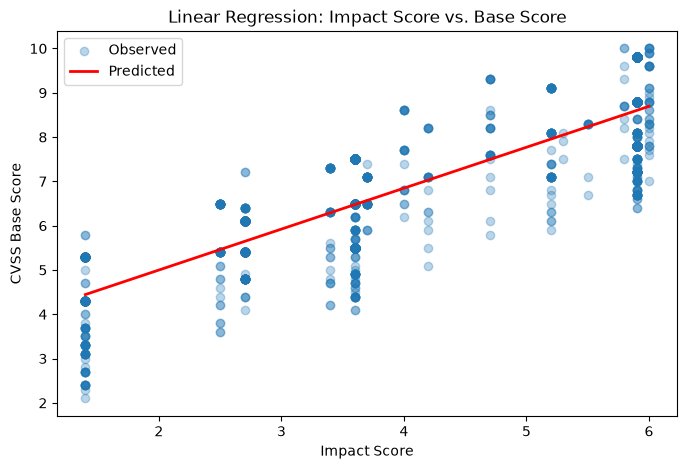

In [8]:
plot_idx = X_test_s.sample(2000, random_state=42).index

line_x = pd.DataFrame({"impact_score": np.linspace(X_s["impact_score"].min(), X_s["impact_score"].max(), 100)})
line_y = simple_lr.predict(line_x)

plt.figure(figsize=(8, 5))
plt.scatter(X_test_s.loc[plot_idx, "impact_score"], y_test_s.loc[plot_idx],
            alpha=0.3, label="Observed")
plt.plot(line_x["impact_score"], line_y, color="red", linewidth=2, label="Predicted")
plt.title("Linear Regression: Impact Score vs. Base Score")
plt.xlabel("Impact Score")
plt.ylabel("CVSS Base Score")
plt.legend()
plt.show()

#### Report:

| Metric | Value |
|---|---|
| R² | 0.7094 |
| MSE | 0.8321 |
| RMSE | 0.9122 |
| MAE | 0.7666 |

The model explains about 71% of the variation in base_score using impact_score alone, which is high for a model with one input. The slope of 0.9238 means each 1-point increase in impact score raises the predicted base score by about 0.92 points.

The RMSE of 0.91 means a typical prediction is off by about 0.9 points on the 0 to 10 scale, and the MAE shows the average error is about 0.77 points. RMSE is larger than MAE because squaring gives more weight to large errors. The gap between them is small, so the model does not make many very large mistakes.

In the plot, the dots form vertical stripes because impact_score only takes certain values. The red line runs through the middle of each stripe, but each stripe spreads over about 3 to 4 points, because CVEs with the same impact score can have different exploitability scores, which this model does not use. That missing information is most of the remaining error. Task 2 adds exploitability_score and cuts the RMSE to about 0.20.

### Task 2: Multiple Linear Regression

We build a multiple linear regression model that predicts **base_score** from three attributes: the two CVSS sub-scores **exploitability_score** and **impact_score**, plus the knowledge-graph count **n_cpe** (number of affected products). Task 1 showed that impact_score alone leaves most of the error unexplained because it ignores exploitability, so we add it here.

**Choosing the attributes:** X_multi holds the three inputs and y_multi holds what we predict (base_score).

In [9]:
# 1. Define features (more than two attributes) and target variable
features = ['exploitability_score', 'impact_score', 'n_cpe']
target = 'base_score'

X_multi = df[features]
y_multi = df[target]


**Splitting the data:** the same 80/20 split as Task 1, with random_state=42, so both models are tested on the same CVEs.

In [10]:
# 2. Split data into training and testing sets
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)


**Training the model:** LinearRegression finds one weight per attribute plus an intercept, then predicts the base score of every test CVE.

In [11]:
# 3. Fit the multiple linear regression model
multi_lr = LinearRegression()
multi_lr.fit(X_train_m, y_train_m)
y_pred_m = multi_lr.predict(X_test_m)


**Measuring performance:** the same R², MSE, RMSE and MAE as Task 1, plus the learned weight of each attribute.

In [12]:
# 4. Calculate error and loss metrics
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
mae_m = mean_absolute_error(y_test_m, y_pred_m)
r2_m = r2_score(y_test_m, y_pred_m)

print("--- Multiple Linear Regression Metrics ---")
print(f"R² Score: {r2_m:.4f}")
print(f"Mean Squared Error (MSE): {mse_m:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_m:.4f}")
print(f"Mean Absolute Error (MAE): {mae_m:.4f}")
print("Coefficients:")
for name, coef in zip(features, multi_lr.coef_):
    print(f"  {name}: {coef:.4f}")
print(f"Intercept: {multi_lr.intercept_:.4f}")

--- Multiple Linear Regression Metrics ---
R² Score: 0.9865
Mean Squared Error (MSE): 0.0387
Root Mean Squared Error (RMSE): 0.1968
Mean Absolute Error (MAE): 0.1404
Coefficients:
  exploitability_score: 0.9569
  impact_score: 0.9709
  n_cpe: -0.0003
Intercept: 0.3940


**Observed vs. predicted plot (mplot3d):** exploitability score and impact score are on the two flat axes and base score goes up. Blue points are the real base scores and red points are the model's predictions, for a random sample of 2,000 test CVEs.

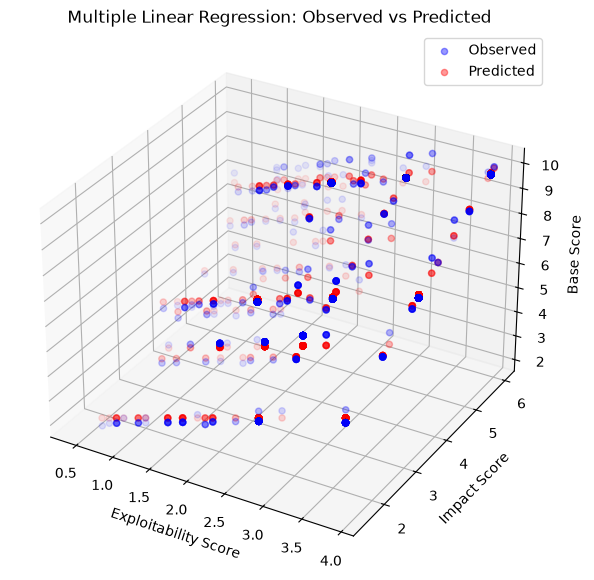

In [13]:
# 5. Draw a 3D plot using mplot3d showing observed vs predicted values
# Random sample of 2,000 test CVEs so the plot stays readable (same idea as Task 1)
plot_idx_m = X_test_m.sample(2000, random_state=42).index
y_pred_m_s = pd.Series(y_pred_m, index=X_test_m.index)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Two main attributes on the X and Y axes, base score on the Z axis
ax.scatter(X_test_m.loc[plot_idx_m, 'exploitability_score'], X_test_m.loc[plot_idx_m, 'impact_score'],
           y_test_m.loc[plot_idx_m], color='blue', label='Observed', alpha=0.4)
ax.scatter(X_test_m.loc[plot_idx_m, 'exploitability_score'], X_test_m.loc[plot_idx_m, 'impact_score'],
           y_pred_m_s.loc[plot_idx_m], color='red', label='Predicted', alpha=0.4)

ax.set_xlabel('Exploitability Score')
ax.set_ylabel('Impact Score')
ax.set_zlabel('Base Score')
ax.set_title('Multiple Linear Regression: Observed vs Predicted')
ax.legend()
plt.show()

#### Report:

| Metric | Task 1 (impact_score only) | Task 2 (three attributes) |
|---|---|---|
| R² | 0.7094 | 0.9865 |
| MSE | 0.8321 | 0.0387 |
| RMSE | 0.9122 | 0.1968 |
| MAE | 0.7666 | 0.1404 |

**Loss functions:** MSE squares each error, so large mistakes count much more than small ones. RMSE is the square root of MSE, which puts the error back on the 0 to 10 base score scale. MAE is the average size of the errors without squaring, so it is less affected by a few large misses.

**Results:** the model explains 98.7% of the variation in base_score. A typical prediction is off by about 0.20 points (RMSE) and the average error is 0.14 points (MAE), which is about 4.6 times smaller than in Task 1. RMSE is only a little larger than MAE, so there are very few large errors.

**Why the fit is almost perfect:** the CVSS v3 formula calculates base_score from the impact and exploitability sub-scores, mostly by adding them and rounding up. The learned weights (0.96 for exploitability_score and 0.97 for impact_score) are close to 1, so the model has nearly rebuilt that formula. The small remaining error comes from the formula's rounding, its cap at 10, and its extra multiplier for CVEs with a changed scope. **n_cpe** has a weight of −0.0003, so the number of affected products adds nothing. Task 6 checks whether it is worth keeping.

**Plot:** in the 3D plot the red predicted points sit on top of, or right next to, the blue observed points for the whole range of both sub-scores.

### Task 3: Logistic Regression

We build a logistic regression model that predicts whether a CVE is **severe**: 1 = HIGH or CRITICAL (base score 7.0 or higher), 0 = LOW or MEDIUM. The inputs are the **8 CVSS v3 metrics** an analyst assigns when scoring a CVE: attack vector, attack complexity, privileges required, user interaction, scope, and the confidentiality, integrity and availability impacts. This is the same model as Part 3a of Progress Report 2. Here it uses the same random 80/20 split as Tasks 1 and 2, so that Task 4 can compare all three models the same way.

**Choosing the attributes:** each CVSS metric is a category (for example attack_vector is NETWORK, ADJACENT_NETWORK, LOCAL or PHYSICAL), so `pd.get_dummies` turns every metric level into its own 0/1 column. y_log is 1 for HIGH/CRITICAL CVEs and 0 otherwise.

In [14]:
from sklearn.metrics import log_loss, ConfusionMatrixDisplay

cvss_cols = ['attack_vector', 'attack_complexity', 'privileges_required', 'user_interaction',
             'scope', 'confidentiality_impact', 'integrity_impact', 'availability_impact']

# One 0/1 column per metric level, e.g. attack_vector=NETWORK
X_log = pd.get_dummies(df[cvss_cols], prefix_sep='=').astype(float)
y_log = df['severity'].isin(['HIGH', 'CRITICAL']).astype(int)

print("Input columns:", X_log.shape[1])
print("Missing CVSS metric values:", int(df[cvss_cols].isna().sum().sum()))
print(f"Share of CVEs that are HIGH/CRITICAL: {y_log.mean():.1%}")

Input columns: 22
Missing CVSS metric values: 0
Share of CVEs that are HIGH/CRITICAL: 54.8%


**Splitting the data:** the same 80/20 split as Tasks 1 and 2 (test_size=0.2, random_state=42). Because df has the same rows in the same order, the test set is the same 61,448 CVEs.

In [15]:
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_log, y_log, test_size=0.2, random_state=42)

print("Training rows:", len(X_train_l))
print("Testing rows: ", len(X_test_l))

Training rows: 245791
Testing rows:  61448


**Training the model:** LogisticRegression learns one weight per metric level. For each CVE it adds up the weights to get a score (the log-odds) and passes it through the sigmoid function to get a probability between 0 and 1. A CVE is predicted HIGH/CRITICAL when that probability is 0.5 or more.

In [16]:
log_lr = LogisticRegression(max_iter=2000)
log_lr.fit(X_train_l, y_train_l)

p_log = log_lr.predict_proba(X_test_l)[:, 1]   # predicted probability of HIGH/CRITICAL
y_pred_l = log_lr.predict(X_test_l)            # predicted class (0 or 1)

**Measuring performance:** we report accuracy and a classification report, plus the two loss functions the assignment asks for.
- **Absolute loss:** the average of |observed − predicted probability|. A confident correct prediction adds almost 0, and a confident wrong one adds almost 1.
- **Log loss:** the average of −[y·log(p) + (1 − y)·log(1 − p)]. It punishes confident wrong predictions much more heavily than absolute loss does.

For comparison we also compute both losses for a baseline that ignores the inputs and gives every CVE the training set's share of HIGH/CRITICAL as its probability.

In [17]:
acc_l = accuracy_score(y_test_l, y_pred_l)
abs_loss_l = np.mean(np.abs(y_test_l - p_log))
log_loss_l = log_loss(y_test_l, p_log)

# Baseline: same probability for every CVE (the share of HIGH/CRITICAL in training)
p_base = np.full(len(y_test_l), y_train_l.mean())
abs_loss_base = np.mean(np.abs(y_test_l - p_base))
log_loss_base = log_loss(y_test_l, p_base)

print("--- Logistic Regression Metrics ---")
print(f"Accuracy:      {acc_l:.4f}")
print(f"Absolute loss: {abs_loss_l:.4f}   (baseline {abs_loss_base:.4f})")
print(f"Log loss:      {log_loss_l:.4f}   (baseline {log_loss_base:.4f})")
print()
print(classification_report(y_test_l, y_pred_l, target_names=['LOW/MEDIUM', 'HIGH/CRITICAL'], digits=3))

--- Logistic Regression Metrics ---
Accuracy:      0.9927
Absolute loss: 0.0182   (baseline 0.4955)
Log loss:      0.0367   (baseline 0.6889)

               precision    recall  f1-score   support

   LOW/MEDIUM      0.990     0.994     0.992     27879
HIGH/CRITICAL      0.995     0.992     0.993     33569

     accuracy                          0.993     61448
    macro avg      0.992     0.993     0.993     61448
 weighted avg      0.993     0.993     0.993     61448



**Observed vs. predicted plot:** the left panel puts each test CVE at its log-odds score (x-axis) and its observed class (y-axis, 0 or 1, spread slightly so the dots do not overlap). The black curve is the predicted probability from the sigmoid. We plot a random sample of 4,000 test CVEs so the plot stays readable. The right panel is the confusion matrix for the whole test set: how many CVEs of each observed class were predicted as each class.

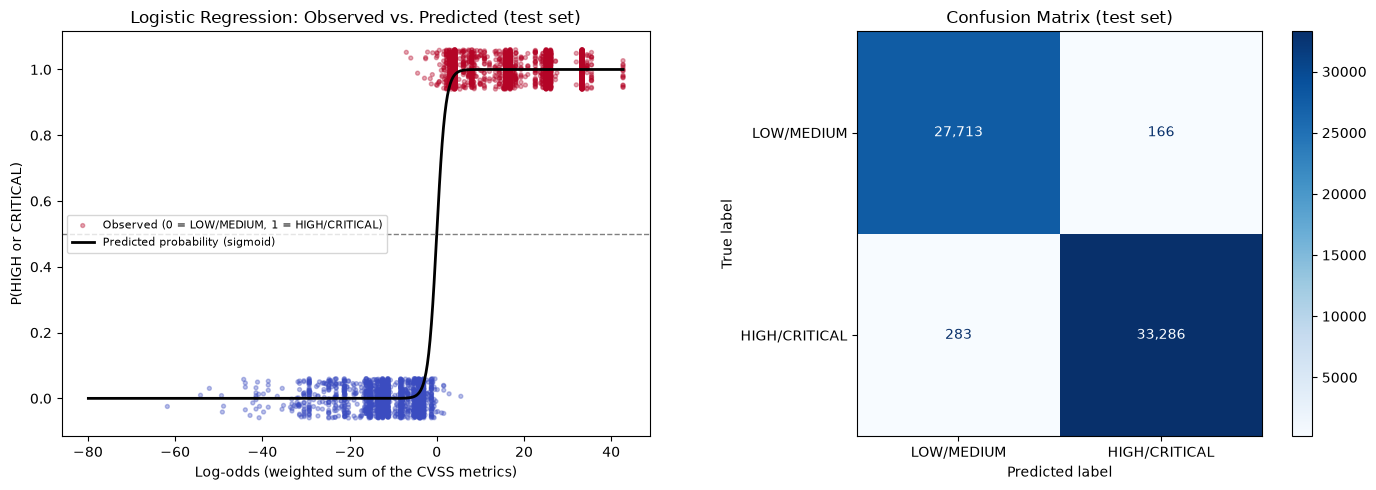

In [18]:
z_l = log_lr.decision_function(X_test_l)            # log-odds for each test CVE
rng = np.random.default_rng(42)
sample_l = rng.choice(len(z_l), 4000, replace=False)
y_obs_l = y_test_l.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
jitter = rng.uniform(-0.06, 0.06, len(sample_l))
ax.scatter(z_l[sample_l], y_obs_l[sample_l] + jitter, c=y_obs_l[sample_l], cmap='coolwarm',
           s=8, alpha=0.35, label='Observed (0 = LOW/MEDIUM, 1 = HIGH/CRITICAL)')
zz = np.linspace(z_l.min(), z_l.max(), 400)
ax.plot(zz, 1 / (1 + np.exp(-zz)), color='black', lw=2, label='Predicted probability (sigmoid)')
ax.axhline(0.5, color='gray', ls='--', lw=1)
ax.set_xlabel('Log-odds (weighted sum of the CVSS metrics)')
ax.set_ylabel('P(HIGH or CRITICAL)')
ax.set_title('Logistic Regression: Observed vs. Predicted (test set)')
ax.legend(loc='center left', fontsize=8)

ConfusionMatrixDisplay.from_predictions(y_test_l, y_pred_l, ax=axes[1],
                                        display_labels=['LOW/MEDIUM', 'HIGH/CRITICAL'],
                                        cmap='Blues', values_format=',')
axes[1].set_title('Confusion Matrix (test set)')
plt.tight_layout()
plt.show()

#### Report:

| Metric | Logistic regression | Baseline (same probability for every CVE) |
|---|---|---|
| Accuracy | 0.9927 | 0.5463 (always predict HIGH/CRITICAL) |
| Absolute loss | 0.0182 | 0.4955 |
| Log loss | 0.0367 | 0.6889 |

**Results:** the model classifies 99.3% of the 61,448 test CVEs correctly. Only 449 are wrong: 166 LOW/MEDIUM CVEs predicted as HIGH/CRITICAL and 283 HIGH/CRITICAL CVEs predicted as LOW/MEDIUM. Precision and recall are both about 0.99 for each class, so the model does equally well on both. A baseline that ignores the inputs gets only 54.6% accuracy, by always guessing the more common class.

**Loss functions:** the absolute loss of 0.018 means the predicted probability is on average only 0.018 away from the true 0 or 1, compared with 0.50 for the baseline. The log loss of 0.037 is about 95% lower than the baseline's 0.689. Log loss is about twice the absolute loss because it punishes confident wrong answers much more: the few misclassified CVEs carry most of the log loss.

**Why the performance is so high:** NVD's base score, and therefore its severity, is calculated by the CVSS formula from exactly these 8 metrics, so the model has almost all the information it needs. The errors are CVEs whose score is close to the 7.0 cut-off. There the formula multiplies the impact values together, which a model that adds up weights cannot match exactly. In Progress Report 2 the same model scored 98.6% when trained on CVEs up to 2024 and tested on 2025–26. The random split here is slightly easier because the training and test CVEs come from the same years.

**Plot:** in the left panel, almost all observed HIGH/CRITICAL CVEs (red) sit to the right of 0, where the predicted probability is close to 1, and almost all LOW/MEDIUM CVEs (blue) sit to the left, where it is close to 0. The two classes only mix in a narrow band around 0, where the probability is near 0.5. The confusion matrix shows the same thing for the whole test set.

**Limitation:** these 8 metrics only exist after an analyst has scored the CVE, so this model shows how well severity can be recovered from the CVSS metrics, not how well it can be predicted for a brand-new CVE. Progress Report 2 showed that using only the description and graph links available at publication, accuracy drops to about 75%.

### Task 4: Cross-Validation

A single train-test split gives one score that depends on which CVEs land in the test set. 5-fold cross-validation trains and tests each model 5 times, so every CVE is tested once, and reports the mean and spread across folds.

**Regression models (Tasks 1 and 2):** `KFold` shuffles the data into 5 folds. `cross_validate` returns the MSE, MAE and R² of each fold.

In [19]:
from sklearn.model_selection import cross_validate, StratifiedKFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_regression(X, y):
    """5-fold CV of a LinearRegression: MSE, RMSE, MAE and R² for each fold."""
    res = cross_validate(LinearRegression(), X, y, cv=kf,
                         scoring=['neg_mean_squared_error', 'neg_mean_absolute_error', 'r2'])
    mse = -res['test_neg_mean_squared_error']
    return pd.DataFrame({'MSE': mse, 'RMSE': np.sqrt(mse),
                         'MAE': -res['test_neg_mean_absolute_error'], 'R²': res['test_r2']},
                        index=pd.RangeIndex(1, 6, name='fold'))

cv_simple = cv_regression(X_s, y_s)          # Task 1
cv_multi = cv_regression(X_multi, y_multi)   # Task 2
print("Task 1 folds:"); display(cv_simple.round(4))
print("Task 2 folds:"); display(cv_multi.round(4))

Task 1 folds:


,MSE,RMSE,MAE,R²
fold,,,,
1,0.8321,0.9122,0.7666,0.7094
2,0.8325,0.9124,0.7684,0.7105
3,0.8324,0.9124,0.7673,0.7090
4,0.8261,0.9089,0.7630,0.7105
5,0.8351,0.9139,0.7695,0.7097


Task 2 folds:


,MSE,RMSE,MAE,R²
fold,,,,
1,0.0387,0.1968,0.1404,0.9865
2,0.0390,0.1974,0.1402,0.9864
3,0.0383,0.1957,0.1394,0.9866
4,0.0390,0.1976,0.1407,0.9863
5,0.0391,0.1978,0.1404,0.9864


**Logistic model (Task 3):** `StratifiedKFold` keeps the same HIGH/CRITICAL share in every fold. Each fold reports accuracy, absolute loss and log loss.

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for fold, (tr, te) in enumerate(skf.split(X_log, y_log), start=1):
    m = LogisticRegression(max_iter=2000).fit(X_log.iloc[tr], y_log.iloc[tr])
    p = m.predict_proba(X_log.iloc[te])[:, 1]
    y_true = y_log.iloc[te]
    rows.append({'fold': fold,
                 'accuracy': accuracy_score(y_true, (p >= 0.5).astype(int)),
                 'absolute loss': np.mean(np.abs(y_true - p)),
                 'log loss': log_loss(y_true, p)})
cv_log = pd.DataFrame(rows).set_index('fold')
display(cv_log.round(4))

,accuracy,absolute loss,log loss
fold,,,
1,0.9929,0.0177,0.0374
2,0.9927,0.0179,0.0360
3,0.9932,0.0177,0.0363
4,0.9932,0.0179,0.0350
5,0.9919,0.0180,0.0393


**Comparison with the single split:** each model's single-split score from Tasks 1–3 next to its CV mean and standard deviation.

In [21]:
def compare(model, metric, split_value, folds):
    return {'model': model, 'metric': metric, 'single split': split_value,
            'CV mean': folds.mean(), 'CV std': folds.std()}

cv_compare = pd.DataFrame([
    compare('Task 1: linear', 'RMSE', rmse_s, cv_simple['RMSE']),
    compare('Task 1: linear', 'MAE', mae_s, cv_simple['MAE']),
    compare('Task 1: linear', 'R²', r2_s, cv_simple['R²']),
    compare('Task 2: multiple linear', 'RMSE', rmse_m, cv_multi['RMSE']),
    compare('Task 2: multiple linear', 'MAE', mae_m, cv_multi['MAE']),
    compare('Task 2: multiple linear', 'R²', r2_m, cv_multi['R²']),
    compare('Task 3: logistic', 'accuracy', acc_l, cv_log['accuracy']),
    compare('Task 3: logistic', 'absolute loss', abs_loss_l, cv_log['absolute loss']),
    compare('Task 3: logistic', 'log loss', log_loss_l, cv_log['log loss']),
]).set_index(['model', 'metric'])
display(cv_compare.round(4))

single split  CV mean  CV std
model                   metric                                      
Task 1: linear          RMSE                 0.9122   0.9119  0.0018
                        MAE                  0.7666   0.7670  0.0025
                        R²                   0.7094   0.7098  0.0007
Task 2: multiple linear RMSE                 0.1968   0.1971  0.0009
                        MAE                  0.1404   0.1403  0.0005
                        R²                   0.9865   0.9864  0.0001
Task 3: logistic        accuracy             0.9927   0.9928  0.0005
                        absolute loss        0.0182   0.0178  0.0001
                        log loss             0.0367   0.0368  0.0017

**Plot:** the 5 fold scores (dots) for each model's main error, with the single-split score as a red line.

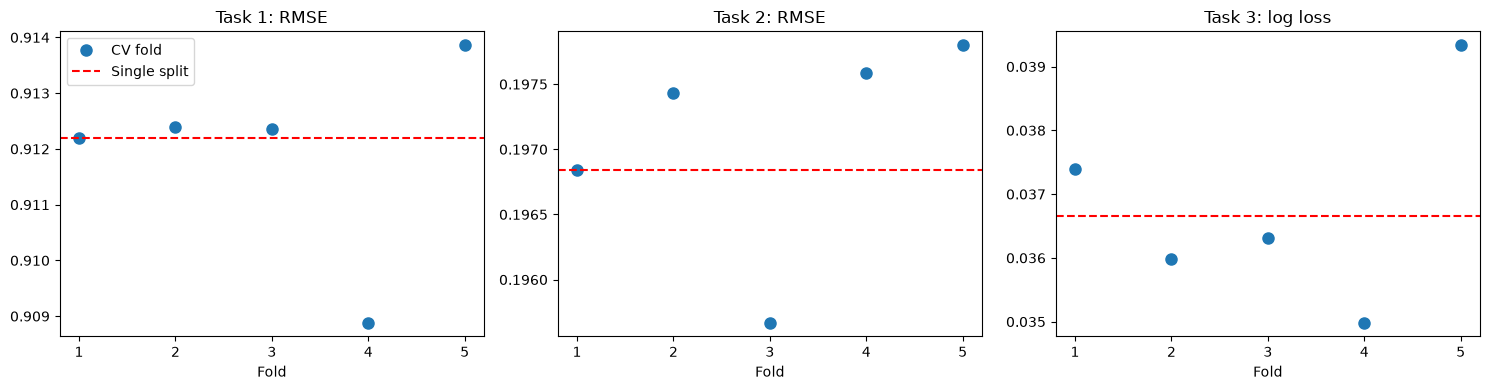

In [22]:
panels = [('Task 1: RMSE', cv_simple['RMSE'], rmse_s),
          ('Task 2: RMSE', cv_multi['RMSE'], rmse_m),
          ('Task 3: log loss', cv_log['log loss'], log_loss_l)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, folds, split_value) in zip(axes, panels):
    ax.plot(folds.index, folds.values, 'o', markersize=8, label='CV fold')
    ax.axhline(split_value, color='red', ls='--', label='Single split')
    ax.set_title(title)
    ax.set_xlabel('Fold')
    ax.set_xticks(folds.index)
axes[0].legend()
plt.tight_layout()
plt.show()

#### Report:

| Model | Metric | Single split | 5-fold CV (mean ± std) |
|---|---|---|---|
| Task 1: linear | RMSE | 0.9122 | 0.9119 ± 0.0018 |
| Task 2: multiple linear | RMSE | 0.1968 | 0.1971 ± 0.0009 |
| Task 3: logistic | accuracy | 0.9927 | 0.9928 ± 0.0005 |
| Task 3: logistic | log loss | 0.0367 | 0.0368 ± 0.0017 |

Every CV mean is within one standard deviation of its single-split score, except Task 3's absolute loss (0.0182 vs. 0.0177–0.0180 across folds, a gap of 0.0004). So the single 80/20 split was a fair estimate and no model depends on a lucky test set. The plot looks spread out only because its y-axes are zoomed in: Task 1's RMSE varies by just 0.005 across folds. The spread is small because each fold still tests about 61,000 CVEs. (Fold 1 uses the same test set as the single split, so its scores match exactly.)

### Task 5: Bootstrap

We apply the bootstrap method to the linear regression model from Task 1 (impact_score → base_score) to see how much its error changes when it is trained on different samples of the data.

**Bootstrapping:** we repeat the following 200 times. We draw a new training set of the same size by picking CVEs from the training data at random with replacement, so some CVEs appear more than once and others not at all. We train a new linear regression model on it and measure its RMSE and MAE on the same test set as Task 1. random_state=i gives each round a different, but repeatable, sample.

In [23]:
from sklearn.utils import resample

n_boot = 200          # number of bootstrap rounds
boot_rmse = []
boot_mae = []

for i in range(n_boot):
    # New training set: same size, picked at random with replacement
    X_b, y_b = resample(X_train_s, y_train_s, random_state=i)

    # Train a new model on it and test on the Task 1 test set
    model_b = LinearRegression().fit(X_b, y_b)
    pred_b = model_b.predict(X_test_s)

    boot_rmse.append(np.sqrt(mean_squared_error(y_test_s, pred_b)))
    boot_mae.append(mean_absolute_error(y_test_s, pred_b))

boot_rmse = np.array(boot_rmse)
boot_mae = np.array(boot_mae)
print("Bootstrap rounds finished:", len(boot_rmse))

Bootstrap rounds finished: 200


**Error mean and standard deviation:** we take the mean and standard deviation of the 200 RMSE and MAE values. The mean is the typical error, and the standard deviation shows how much the error changes from one training sample to another. We also compare the mean to the single train-test split from Task 1.

In [24]:
print("--- Bootstrap Results (200 rounds) ---")
print(f"RMSE: mean = {boot_rmse.mean():.4f}, standard deviation = {boot_rmse.std():.6f}")
print(f"MAE:  mean = {boot_mae.mean():.4f}, standard deviation = {boot_mae.std():.6f}")
print()
print(f"Task 1 single split: RMSE = {rmse_s:.4f}, MAE = {mae_s:.4f}")

--- Bootstrap Results (200 rounds) ---
RMSE: mean = 0.9122, standard deviation = 0.000013
MAE:  mean = 0.7666, standard deviation = 0.000251

Task 1 single split: RMSE = 0.9122, MAE = 0.7666


**Distribution of the bootstrap errors:** a histogram of the 200 RMSE values. The red line marks the RMSE from the single split in Task 1.

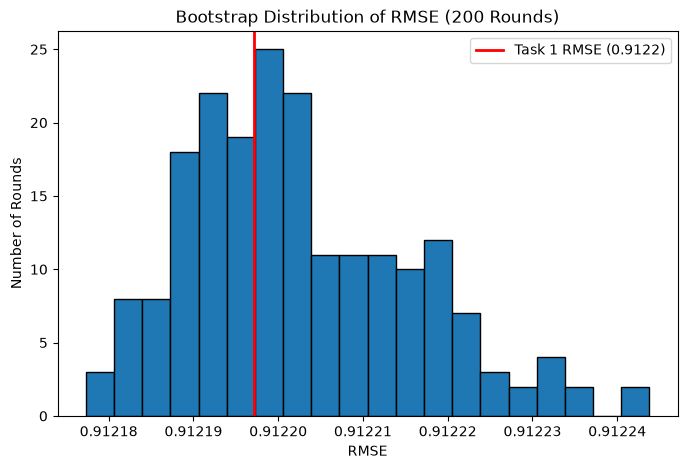

In [25]:
plt.figure(figsize=(8, 5))
plt.hist(boot_rmse, bins=20, edgecolor="black")
plt.axvline(rmse_s, color="red", linewidth=2, label=f"Task 1 RMSE ({rmse_s:.4f})")
plt.title("Bootstrap Distribution of RMSE (200 Rounds)")
plt.xlabel("RMSE")
plt.ylabel("Number of Rounds")
plt.legend()
plt.show()

#### Report:

| Error | Bootstrap mean | Bootstrap standard deviation | Task 1 single split |
|---|---|---|---|
| RMSE | 0.9122 | 0.000013 | 0.9122 |
| MAE | 0.7666 | 0.000251 | 0.7666 |

The bootstrap means equal the Task 1 single-split errors, so that split gave a fair picture of the model's performance.

The standard deviations are extremely small. In the histogram, all 200 RMSE values fall between 0.91218 and 0.91224, and the Task 1 RMSE (red line) sits in the middle of them. This is because every bootstrap sample still contains about 245,000 CVEs, so resampling barely changes the fitted line. The model is very stable: its error comes from what impact_score cannot explain (mainly exploitability), not from which CVEs it happened to be trained on.

These standard deviations only measure how much the fitted model changes between training samples, because every round is tested on the same Task 1 test set. Task 4's cross-validation also changes the test set, so its spread is larger.

### Task 6: Comparing Models (Adjusted R² and One-Standard-Error Rule)

Adding an attribute to a linear regression never lowers its R² on the training data, so a bigger model always looks at least as good. Both methods in this section correct for that and ask whether extra attributes are worth keeping.

We compare four nested models that all predict **base_score**. Each one adds attributes to the one before it:
- **M1:** impact_score (the Task 1 model)
- **M2:** + exploitability_score
- **M3:** + n_cpe (the Task 2 model)
- **M4:** + the other three knowledge-graph counts (n_cwe, n_capec, n_attack)

**Defining the candidate models:** each entry lists the attributes one model uses.

In [26]:
candidates = {
    'M1: impact':             ['impact_score'],
    'M2: + exploitability':   ['impact_score', 'exploitability_score'],
    'M3: + n_cpe (Task 2)':   ['impact_score', 'exploitability_score', 'n_cpe'],
    'M4: + all graph counts': ['impact_score', 'exploitability_score', 'n_cpe', 'n_cwe', 'n_capec', 'n_attack'],
}
y_cmp = df['base_score']

#### Method 1: Adjusted R²

**Adjusted R²** lowers R² by a penalty for each attribute: adjusted R² = 1 − (1 − R²)(n − 1)/(n − p − 1), where n is the number of rows and p the number of attributes. It only goes up when a new attribute improves the fit by more than chance would. The cell fits each model on the same 80/20 split as Tasks 1 and 2 and reports R² and adjusted R² on the training data, plus R² on the test data.

In [27]:
def adjusted_r2(r2, n, p):
    """Adjusted R²: n = number of rows, p = number of attributes."""
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

adj_rows = []
for name, cols in candidates.items():
    X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(df[cols], y_cmp, test_size=0.2, random_state=42)
    model_c = LinearRegression().fit(X_tr_c, y_tr_c)
    r2_tr = r2_score(y_tr_c, model_c.predict(X_tr_c))
    adj_rows.append({'model': name,
                     'attributes': len(cols),
                     'R² (train)': r2_tr,
                     'adjusted R² (train)': adjusted_r2(r2_tr, len(X_tr_c), len(cols)),
                     'R² (test)': r2_score(y_te_c, model_c.predict(X_te_c))})

adj_table = pd.DataFrame(adj_rows).set_index('model')
adj_table['gain over previous model'] = adj_table['adjusted R² (train)'].diff()
display(adj_table.round(6))

,attributes,R² (train),adjusted R² (train),R² (test),gain over previous model
model,,,,,
M1: impact,1,0.709925,0.709923,0.709380,NaN
M2: + exploitability,2,0.986437,0.986436,0.986455,0.276513
M3: + n_cpe (Task 2),3,0.986445,0.986445,0.986468,0.000009
M4: + all graph counts,6,0.986704,0.986704,0.986722,0.000259


#### Method 2: One-standard-error rule

The **one-standard-error rule** uses cross-validation. For each model we run 10-fold cross-validation and record the mean test MSE and its standard error (the standard deviation of the 10 fold MSEs divided by √10). We find the model with the lowest mean MSE, then choose the **simplest** model whose mean MSE is no more than one standard error above it. Models inside that band cannot be told apart from the best one, so the rule prefers fewer attributes.

In [28]:
kf10 = KFold(n_splits=10, shuffle=True, random_state=42)

cv_rows = []
for name, cols in candidates.items():
    fold_mse = -cross_val_score(LinearRegression(), df[cols], y_cmp, cv=kf10, scoring='neg_mean_squared_error')
    cv_rows.append({'model': name,
                    'attributes': len(cols),
                    'CV MSE (mean)': fold_mse.mean(),
                    'standard error': fold_mse.std(ddof=1) / np.sqrt(len(fold_mse))})
cv_table = pd.DataFrame(cv_rows).set_index('model')

# Best model, the one-SE threshold, and the simplest model under that threshold
best_model = cv_table['CV MSE (mean)'].idxmin()
threshold = cv_table.loc[best_model, 'CV MSE (mean)'] + cv_table.loc[best_model, 'standard error']
cv_table['within 1 SE of best'] = cv_table['CV MSE (mean)'] <= threshold
chosen_model = cv_table[cv_table['within 1 SE of best']]['attributes'].idxmin()

display(cv_table.round(6))
print(f"Lowest mean CV MSE:          {best_model} ({cv_table.loc[best_model, 'CV MSE (mean)']:.6f})")
print(f"One-SE threshold:            {threshold:.6f}")
print(f"Chosen by the one-SE rule:   {chosen_model}")

,attributes,CV MSE (mean),standard error,within 1 SE of best
model,,,,
M1: impact,1,0.831634,0.001897,False
M2: + exploitability,2,0.038861,0.000150,False
M3: + n_cpe (Task 2),3,0.038835,0.000147,False
M4: + all graph counts,6,0.038096,0.000156,True


Lowest mean CV MSE:          M4: + all graph counts (0.038096)
One-SE threshold:            0.038252
Chosen by the one-SE rule:   M4: + all graph counts


**Plot:** mean CV MSE for each model with one-standard-error bars. The left panel shows all four models. M1's error is about 20 times larger than the others, so the right panel zooms in on M2 to M4, with the one-SE threshold as a red dashed line.

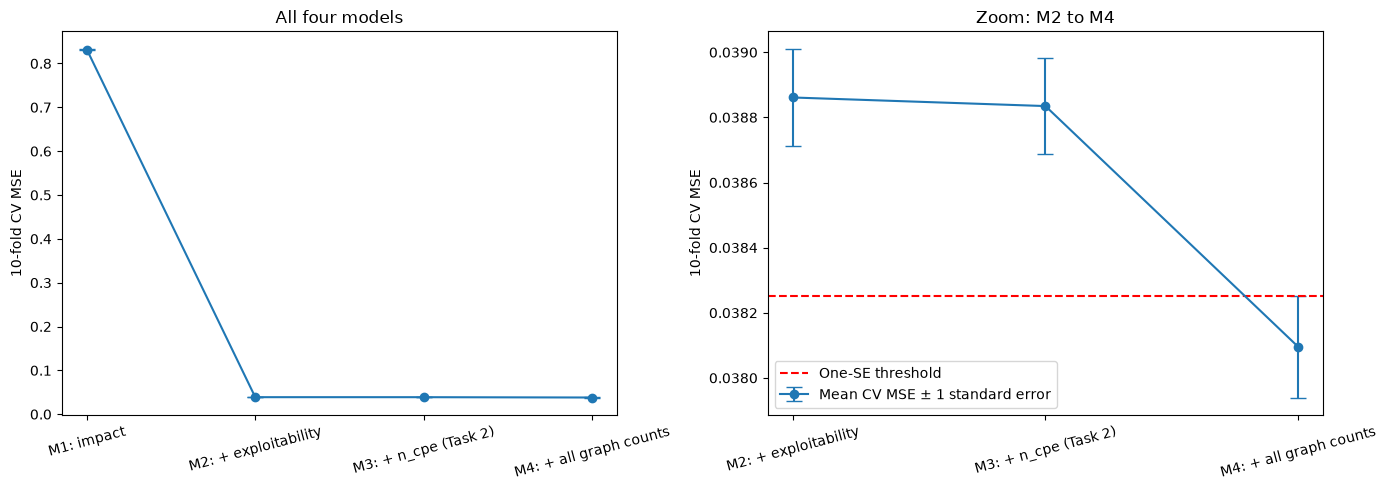

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, table in [(axes[0], cv_table), (axes[1], cv_table.iloc[1:])]:
    x = np.arange(len(table))
    ax.errorbar(x, table['CV MSE (mean)'], yerr=table['standard error'],
                fmt='o-', capsize=6, label='Mean CV MSE ± 1 standard error')
    ax.set_xticks(x)
    ax.set_xticklabels(table.index, rotation=15)
    ax.set_ylabel('10-fold CV MSE')

axes[0].set_title('All four models')
axes[1].axhline(threshold, color='red', ls='--', label='One-SE threshold')
axes[1].set_title('Zoom: M2 to M4')
axes[1].legend()
plt.tight_layout()
plt.show()

#### Report:

| Model | Attributes | Adjusted R² (train) | 10-fold CV MSE | Standard error | Within 1 SE of best |
|---|---|---|---|---|---|
| M1: impact | 1 | 0.7099 | 0.8316 | 0.0019 | No |
| M2: + exploitability | 2 | 0.9864 | 0.03886 | 0.00015 | No |
| M3: + n_cpe (Task 2) | 3 | 0.9864 | 0.03884 | 0.00015 | No |
| M4: + all graph counts | 6 | 0.9867 | 0.03810 | 0.00016 | Yes (best) |

**Adjusted R²:** with about 246,000 training rows, the penalty for each extra attribute is tiny, so adjusted R² and R² agree to five or six decimal places. Adding exploitability_score (M1 → M2) raises adjusted R² by 0.277, the only large jump. Adding n_cpe (M3) raises it by only 0.000009, which is effectively nothing. Adding the other three graph counts (M4) raises it by 0.00026. Test R² ranks the models in the same order, so none of them is overfitting.

**One-standard-error rule:** M4 has the lowest mean CV MSE (0.03810). The one-SE threshold is 0.03825, and M2 and M3 sit about five standard errors above the best model, outside that band, so the rule chooses **M4**. The difference between M2 and M3 (0.00003) is much smaller than one standard error (0.00015), which confirms that n_cpe is not worth keeping, as Task 2 suggested.

**How big is the gain?** M4's improvement is real (it is far larger than the fold-to-fold noise) but small in practice. RMSE drops from about 0.197 (M2) to 0.195 (M4), so predictions improve by about 0.002 points on the 0 to 10 scale. A likely reason the graph counts help at all is that the CVSS formula multiplies the score for CVEs with a changed scope, which a purely additive model cannot reproduce, and the type of weakness a CVE links to in the graph (its CWE, CAPEC and ATT&CK links) is related to whether its scope changes.

**Result:** both methods agree that exploitability_score is essential and n_cpe adds nothing. The one-SE rule selects M4: the other graph counts carry a small but real signal beyond the CVSS sub-scores.

### Conclusion

| Task | Result |
|---|---|
| 1. Linear regression | impact_score → base_score: R² 0.71, RMSE 0.91 |
| 2. Multiple linear regression | + exploitability_score and n_cpe: R² 0.987, RMSE 0.20 |
| 3. Logistic regression | 8 CVSS metrics → HIGH/CRITICAL: 99.3% accuracy, log loss 0.037 |
| 4. Cross-validation | 5-fold CV matched the single split for all three models |
| 5. Bootstrap | Task 1 RMSE over 200 rounds: 0.9122 ± 0.000013 |
| 6. Model comparison | exploitability_score is essential, n_cpe adds nothing; the one-SE rule picks the model with all graph counts |

**What we learned:**
- **High scores can mislead.** Tasks 2 and 3 are near-perfect because their inputs are the pieces the CVSS formula uses to calculate the score. Predicting severity before a CVE is scored is much harder (about 75% in Progress Report 2).
- **With 300,000 CVEs, one split is reliable.** Cross-validation and bootstrap barely moved the scores. The flip side is that tiny gains become statistically significant, so their practical size matters too.
- **The graph adds a small, real signal.** The CWE, CAPEC and ATT&CK counts lowered the error by about 2% beyond the CVSS sub-scores, while n_cpe added nothing. Our planned GNN will test whether the full graph structure can add more.